# Sesión 3: Projected GAN | El espacio abstracto

**Arqueología de la I.A. generativa · Taller MUTAR**

**Año de referencia:** 2021 | **Modelo:** Projected GAN (Autonomous Vision Group, Universidad de Tubinga)

---

### Antes de empezar

1. **Haz tu propia copia:** `Archivo → Guardar una copia en Drive`.
2. **Activa la GPU:** `Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU → Guardar`.
3. **Ejecuta las celdas en orden**, de arriba hacia abajo (botón ▶ o `Ctrl + Enter`).
4. Las celdas con **formulario** se modifican sin tocar el código: cambia el valor a la derecha y vuelve a ejecutar solo esa celda.

**No necesitas saber programar.**

### Qué haremos hoy

1. **Lugares:** explorar habitaciones que parecen habitaciones, pero donde no se puede nombrar ningún objeto (modelo `bedroom`).
2. **Criaturas:** mirar el **vecindario** de una imagen con un modelo entrenado con Pokémon (modelo `pokemon`).
3. **Experimentos:** **disolver** una imagen desde adentro del generador y pintar en un **lienzo expandido**, más grande que lo que el modelo sabe hacer.
4. **Videos:** viajar entre semillas, disolverse, y recorrer habitaciones que se continúan unas en otras.

**Te llevas:** imágenes y videos. Los vamos a usar en la Sesión 4 (FILM).

## ¿Qué es Projected GAN?

En la Sesión 2 vimos que una GAN son dos redes que compiten: un **generador** que fabrica imágenes y un **discriminador** que intenta descubrir cuáles son falsas.

**Projected GAN** (Axel Sauer, Kashyap Chitta, Jens Müller y Andreas Geiger, 2021) cambia al detective. En lugar de entrenar un discriminador desde cero, lo hace mirar a través de una **red ya entrenada**, EfficientNet, como si fuera una lente. Esa red ya sabe distinguir texturas, formas y objetos, así que el detective aprende mucho más rápido. Según los autores, el entrenamiento llega a ser **hasta 40 veces más rápido** y funciona con conjuntos de datos chicos.

> Dato arqueológico: EfficientNet es una red de clasificación, como Inception, entrenada con **ImageNet**: las mismas 1000 categorías de las sesiones 1 y 2. Aunque hoy generemos habitaciones o criaturas, la mirada que juzga si una imagen "parece real" sigue siendo la de ImageNet.

### Los dos mundos de hoy

* **bedroom (lugares):** aprendió de un dataset de unos **3 millones de fotos de dormitorios** (LSUN Bedroom). La red aprende muy bien la *apariencia* de un cuarto: cómo cae la luz, qué colores van juntos, dónde suele estar la cama. Pero nadie le dijo nunca qué es una lámpara o una cortina. Por eso sus habitaciones parecen habitaciones hasta que intentas nombrar lo que hay en ellas.
* **pokemon (criaturas):** aprendió de **833 ilustraciones** de Pokémon sobre fondo blanco. Con tan pocos ejemplos, genera seres que *casi* son Pokémon.

### El generador

Todos estos modelos usan **FastGAN** (Bingchen Liu y equipo, 2021), un generador liviano pensado para entrenar con pocas imágenes. Genera imágenes de **256 × 256 píxeles**.

* **Sin clases:** a diferencia de BigGAN, no le pedimos "iglesia" ni "medusa". Solo hay **ruido**: 256 números al azar.
* **Semilla:** fija esos 256 números. Misma semilla, misma imagen.

> **¿Y la truncación?** Estos modelos no la tienen. FastGAN **normaliza** el ruido apenas entra: lo lleva siempre a la misma escala. Por eso achicar los números, como hacía la truncación de BigGAN, no cambia nada. No todas las GANs tienen las mismas perillas: hoy vamos a inventar otras (sección 5).

In [1]:
#@title 0. Preparar el entorno (ejecutar primero)
import os, sys, subprocess, time, glob, shutil, contextlib
if not os.path.exists("/content/projected_gan"):
    subprocess.run(["git", "clone", "-q", "https://github.com/autonomousvision/projected_gan.git", "/content/projected_gan"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm==0.4.12", "imageio-ffmpeg"], check=True)
sys.path.insert(0, "/content/projected_gan")

import numpy as np
import torch
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Video
from tqdm.auto import tqdm
from google.colab import files, drive
import dnnlib, legacy
from pg_modules.networks_fastgan import normalize_second_moment

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if dispositivo.type == "cuda":
    print("GPU activada:", torch.cuda.get_device_name(0))
else:
    print("ATENCIÓN: no hay GPU activa. Funciona, pero más lento.")
    print("Ve a Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU → Guardar,")
    print("y vuelve a ejecutar esta celda.")

CARPETA = "/content/resultados/sesion3"
os.makedirs(CARPETA, exist_ok=True)

GPU activada: Tesla T4


### 0.1 Guardar en tu Google Drive (recomendado)

Todo lo que generes queda guardado en tu Drive, en la misma carpeta del taller:

```
Mi unidad/
└── Taller_MUTAR/
    ├── sesion1/
    ├── sesion2/
    ├── sesion3/   ← esta sesión
    └── ...
```

Si prefieres no conectar Drive, desmarca la casilla: los resultados quedan en Colab y los descargas al final (sección 7).

In [2]:
#@title 0.1 Elegir dónde guardar
GUARDAR_EN_DRIVE = True #@param {type:"boolean"}
CARPETA_TALLER = "/content/drive/MyDrive/Taller_MUTAR" #@param {type:"string"}

if GUARDAR_EN_DRIVE:
    try:
        drive.mount("/content/drive")
        CARPETA = os.path.join(CARPETA_TALLER, "sesion3")
        os.makedirs(CARPETA, exist_ok=True)
    except Exception as e:
        print("No se pudo conectar Drive (permite las ventanas emergentes y usa la misma cuenta de Google que en Colab).")
        print("Los resultados se guardarán solo en Colab:", e)
print("Los resultados se guardarán en:", CARPETA)

Mounted at /content/drive
Los resultados se guardarán en: /content/drive/MyDrive/Taller_MUTAR/sesion3


## 1. Cargar el modelo

Empezamos con **bedroom**. Las secciones 3 y 3.1 usan el modelo que elijas aquí. Las demás secciones tienen **su propio menú de modelo**: si eliges uno que no está cargado, se descarga solo, y queda en memoria para no volver a descargarlo.

Todos generan imágenes de 256 × 256 píxeles.

| Modelo | Aprendió de |
|---|---|
| bedroom | un dataset de unos 3 millones de fotos de dormitorios (LSUN) |
| pokemon | 833 ilustraciones de Pokémon |
| church | fotos de iglesias (LSUN) |
| cityscapes | fotos de calles tomadas desde un auto |
| art_painting | unas 1000 pinturas de WikiArt |
| landscape | fotos de paisajes |
| flowers | fotos de flores (Oxford Flowers) |
| clevr | escenas sintéticas de objetos 3D simples |
| ffhq | retratos de rostros |

In [3]:
#@title 1. Cargar el modelo
MODELO = "bedroom" #@param ["bedroom", "pokemon", "church", "cityscapes", "art_painting", "landscape", "flowers", "clevr", "ffhq"]

MODELOS = {}   # los modelos ya cargados quedan aquí

def cargar(nombre):
    if nombre not in MODELOS:
        url = f"https://s3.eu-central-1.amazonaws.com/avg-projects/projected_gan/models/{nombre}.pkl"
        print(f"Descargando {nombre}... (la primera vez tarda un poco)")
        with dnnlib.util.open_url(url) as f:
            MODELOS[nombre] = legacy.load_network_pkl(f)["G_ema"].to(dispositivo).eval()
    return MODELOS[nombre]

G = cargar(MODELO)
RESOLUCION = G.img_resolution
LOTE = 24   # imágenes por tanda en los videos
print(f"Modelo cargado: {MODELO} · imágenes de {RESOLUCION} x {RESOLUCION} px · ruido de {G.z_dim} números")

Descargando bedroom... (la primera vez tarda un poco)
Modelo cargado: bedroom · imágenes de 256 x 256 px · ruido de 256 números


## 2. El motor de generación

Define las funciones que convierten semillas en imágenes, y las de los experimentos de la sección 5. No hace falta modificarla: solo ejecútala.

In [4]:
#@title 2. Motor de generación (solo ejecutar)
Z_DIM = 256

def ruido(semilla):
    # Los 256 números al azar de una semilla.
    return torch.from_numpy(np.random.RandomState(int(semilla)).randn(Z_DIM)).float()

def a_imagen(t):
    a = (t.permute(1, 2, 0) * 127.5 + 128).clamp(0, 255).to(torch.uint8).cpu().numpy()
    return Image.fromarray(a, "RGB")

# --- Disolver: agrega ruido dentro del generador, en las capas que elijas ---
CAPAS = {
    "todas": ["feat_8", "feat_16", "feat_32", "feat_64", "feat_128", "feat_256"],
    "chicas (estructura)": ["feat_8", "feat_16", "feat_32"],
    "grandes (textura)": ["feat_64", "feat_128", "feat_256"],
}

@contextlib.contextmanager
def disolucion(G, nivel=0.0, capas="todas"):
    # Mientras está activa, cada capa elegida recibe ruido proporcional a su propia intensidad.
    ganchos = []
    if nivel > 0:
        def agregar_ruido(modulo, entrada, salida):
            return salida + nivel * salida.std() * torch.randn_like(salida)
        for nombre in CAPAS[capas]:
            ganchos.append(getattr(G.synthesis, nombre).register_forward_hook(agregar_ruido))
    try:
        yield
    finally:
        for g in ganchos:
            g.remove()

@torch.no_grad()
def generar(zs, G, nivel=0.0, capas="todas", ruido_quieto=True):
    # zs: lista de vectores de ruido · devuelve lista de imágenes.
    # FastGAN agrega un poco de ruido extra en cada capa. Lo fijamos (manual_seed)
    # para que la misma semilla dé siempre la misma imagen y los videos no titilen.
    etiqueta = torch.zeros([1, G.c_dim], device=dispositivo)
    salida = []
    with disolucion(G, nivel, capas):
        for z in zs:
            if ruido_quieto:
                torch.manual_seed(0)
            salida.append(a_imagen(G(z[None].to(dispositivo), etiqueta)[0]))
    return salida

# --- Lienzo expandido: varias semillas cosidas en una sola imagen grande ---
def ruidos_lienzo(semilla_inicial, columnas, filas):
    # Una semilla por casilla, seguidas: semilla_inicial, semilla_inicial + 1, ...
    return torch.stack([torch.stack([ruido(semilla_inicial + f * columnas + c) for c in range(columnas)])
                        for f in range(filas)])   # forma: filas x columnas x 256

@torch.no_grad()
def generar_lienzo(zs_lienzo, G, nivel=0.0, capas="todas"):
    # El generador arranca de una grilla de 4 x 4 por semilla. Pegamos esas grillas
    # una al lado de la otra y dejamos que el resto de la red pinte todo junto.
    S = G.synthesis
    filas, columnas, _ = zs_lienzo.shape
    with disolucion(G, nivel, capas):
        torch.manual_seed(0)
        z = normalize_second_moment(zs_lienzo.reshape(-1, Z_DIM).to(dispositivo))
        inicio = S.init(z)                                   # (filas*columnas) x canales x 4 x 4
        c, h, w = inicio.shape[1:]
        inicio = inicio.reshape(filas, columnas, c, h, w).permute(2, 0, 3, 1, 4).reshape(1, c, filas * h, columnas * w)
        f8 = S.feat_8(inicio)
        f16 = S.feat_16(f8)
        f32 = S.feat_32(f16)
        f64 = S.se_64(inicio, S.feat_64(f32))
        f128 = S.se_128(f8, S.feat_128(f64))
        f256 = S.se_256(f16, S.feat_256(f128))
        return a_imagen(S.to_big(f256)[0])

# --- Utilidades ---
def slerp(a, b, t):
    # Interpolación "esférica": recorre el camino entre dos ruidos a velocidad pareja.
    an, bn = a / a.norm(dim=-1, keepdim=True), b / b.norm(dim=-1, keepdim=True)
    omega = torch.acos((an * bn).sum(-1, keepdim=True).clamp(-1, 1))
    lineal = (1 - t) * a + t * b
    esferica = (torch.sin((1 - t) * omega) * a + torch.sin(t * omega) * b) / torch.sin(omega).clamp_min(1e-6)
    return torch.where(omega.abs() < 1e-4, lineal, esferica)

def suavizar(t):
    return t * t * (3 - 2 * t)

def fuente(tam=15):
    try:
        from matplotlib import font_manager
        return ImageFont.truetype(font_manager.findfont("DejaVu Sans"), tam)
    except Exception:
        return ImageFont.load_default()

def grilla(imagenes, etiquetas=None, columnas=4, lado=256):
    filas = (len(imagenes) + columnas - 1) // columnas
    alto_txt = 26 if etiquetas else 0
    hoja = Image.new("RGB", (columnas * lado, filas * (lado + alto_txt)), "white")
    d, f = ImageDraw.Draw(hoja), fuente()
    for k, im in enumerate(imagenes):
        x, y = (k % columnas) * lado, (k // columnas) * (lado + alto_txt)
        hoja.paste(im.resize((lado, lado), Image.LANCZOS), (x, y))
        if etiquetas:
            d.text((x + 6, y + lado + 4), etiquetas[k], fill=(0, 0, 0), font=f)
    return hoja

def guardar(img, nombre_archivo):
    ruta = os.path.join(CARPETA, nombre_archivo)
    img.save(ruta)
    print("Guardado:", ruta)
    return ruta

def ampliar(img, factor):
    return img if factor == 1 else img.resize((img.width * factor, img.height * factor), Image.LANCZOS)

def limpio(texto):
    return "".join(c if c.isalnum() else "_" for c in str(texto))

print("Motor listo.")

Motor listo.


## 3. Explorar semillas

Genera muchas imágenes de una vez, con semillas seguidas a partir de **DESDE**. Es la mejor forma de recorrer el modelo: cada semilla es un punto distinto del espacio latente.

Con **bedroom**, mira cada habitación de cerca: ¿puedes nombrar los objetos? ¿Qué es esa cosa junto a la cama?

Anota los números de las semillas que te gusten: los vas a usar más adelante.

/tmp/ipykernel_1203/2839151098.py:10: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(a, "RGB")


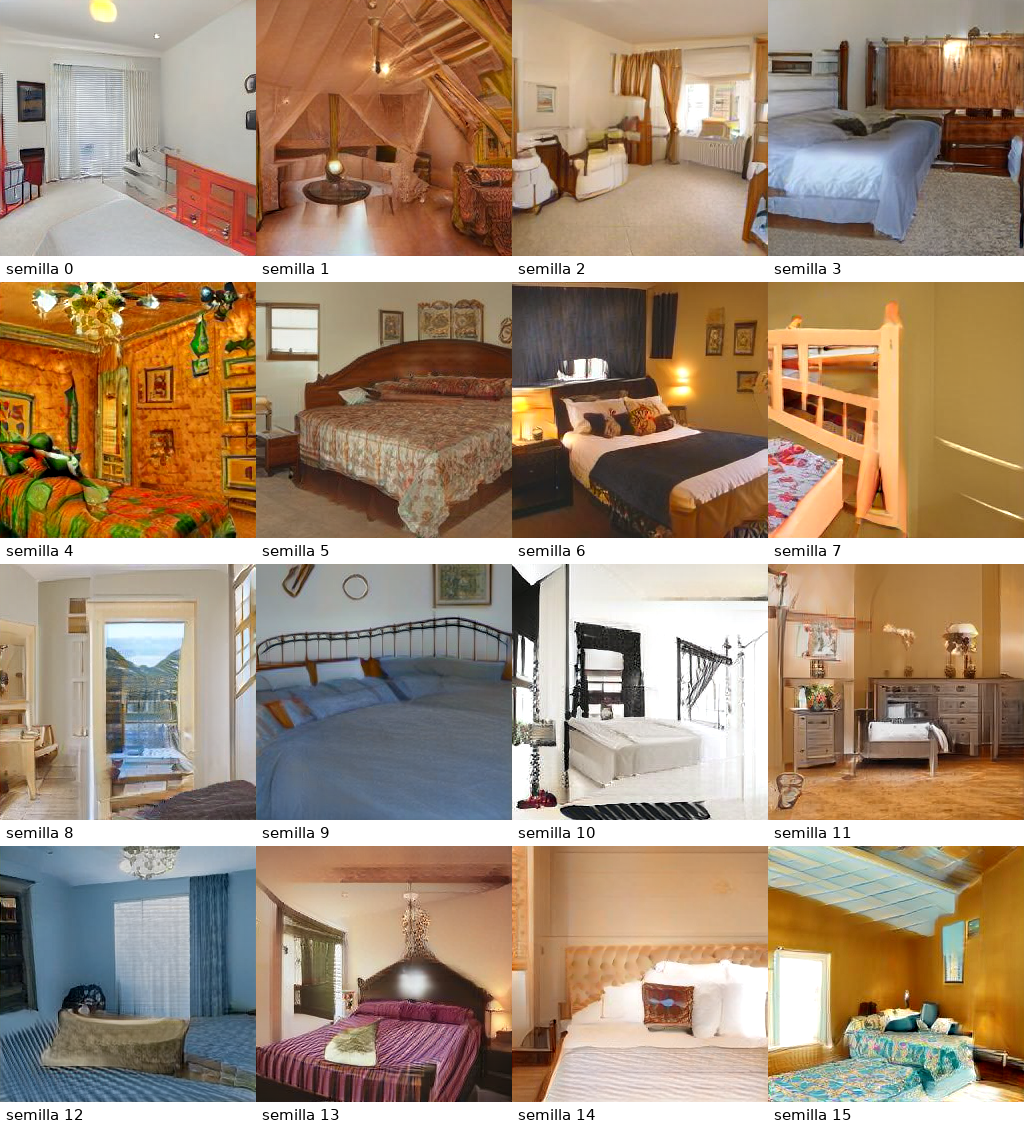

Guardado: /content/drive/MyDrive/Taller_MUTAR/sesion3/bedroom_semillas_0-15.png


'/content/drive/MyDrive/Taller_MUTAR/sesion3/bedroom_semillas_0-15.png'

In [5]:
#@title 3. Explorar semillas (usa el modelo de la celda 1)
DESDE = 0 #@param {type:"integer"}
CANTIDAD = 16 #@param [4, 8, 12, 16, 24, 32] {type:"raw"}

semillas = list(range(DESDE, DESDE + CANTIDAD))
imgs = generar([ruido(s) for s in semillas], G)
hoja = grilla(imgs, [f"semilla {s}" for s in semillas], columnas=4)
display(hoja)
guardar(hoja, f"{MODELO}_semillas_{DESDE}-{DESDE + CANTIDAD - 1}.png")

### 3.1 Una semilla en grande

¿Te gustó una? Escribe su número para guardarla sola. **AMPLIAR** la agranda (no agrega detalle: el modelo genera 256 px). Para imágenes grandes *con* detalle, mira el lienzo expandido (sección 5.2).

/tmp/ipykernel_1203/2839151098.py:10: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(a, "RGB")


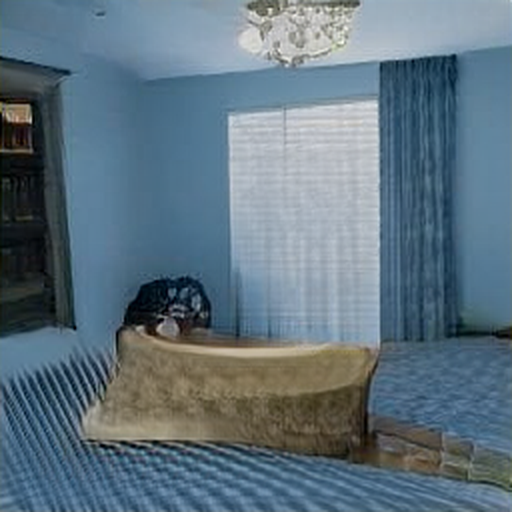

Guardado: /content/drive/MyDrive/Taller_MUTAR/sesion3/bedroom_semilla12_x2.png


'/content/drive/MyDrive/Taller_MUTAR/sesion3/bedroom_semilla12_x2.png'

In [36]:
#@title 3.1 Una semilla en grande (usa el modelo de la celda 1)
SEMILLA = 12 #@param {type:"integer"}
AMPLIAR_IMG = 2 #@param [1, 2, 4] {type:"raw"}

img = ampliar(generar([ruido(SEMILLA)], G)[0], AMPLIAR_IMG)
display(img)
guardar(img, f"{MODELO}_semilla{SEMILLA}_x{AMPLIAR_IMG}.png")

## 4. El vecindario de una imagen

Cada semilla es un punto en un espacio de 256 dimensiones. ¿Qué hay alrededor? Esta celda toma tu semilla (al centro) y genera ocho **vecinas**, moviéndose un poco en direcciones al azar.

Te proponemos verlo con **pokemon**: con una criatura es más fácil notar qué cambia y qué se mantiene. Puedes cambiar el modelo en el menú.

* **DISTANCIA baja (0.1–0.3):** variaciones de la misma criatura: cambia el color, una pata, la postura.
* **DISTANCIA alta (0.6–1.0):** te alejas tanto que aparecen criaturas distintas.

Es la idea de "qué tanto me alejo de lo conocido", la misma que la truncación de BigGAN, pero alrededor de un punto que tú eliges.

**SEMILLA_DIRECCIONES** elige hacia dónde se mueven las ocho vecinas. Cámbiala para ver otras vecinas a la misma distancia.

/tmp/ipykernel_1203/2839151098.py:10: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(a, "RGB")


pokemon: al centro, la semilla 7. Alrededor, ocho vecinas a distancia 0.8.


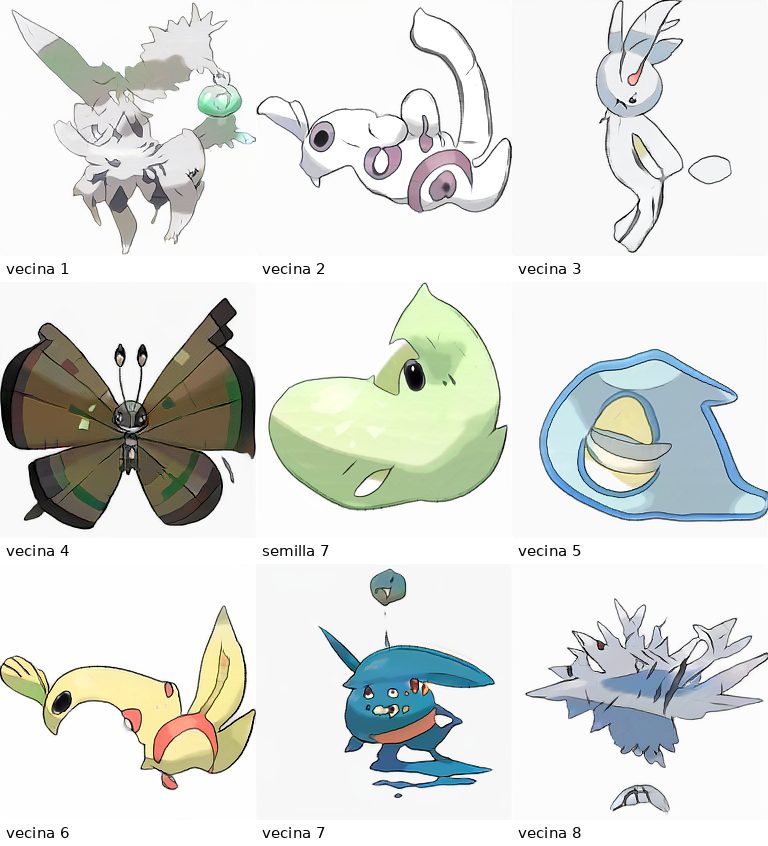

Guardado: /content/drive/MyDrive/Taller_MUTAR/sesion3/pokemon_vecindario_s7_d0.8.png


'/content/drive/MyDrive/Taller_MUTAR/sesion3/pokemon_vecindario_s7_d0.8.png'

In [8]:
#@title 4. Vecindario de una semilla
MODELO_VECINDARIO = "pokemon" #@param ["bedroom", "pokemon", "church", "cityscapes", "art_painting", "landscape", "flowers", "clevr", "ffhq"]
SEMILLA_CENTRO = 7 #@param {type:"integer"}
DISTANCIA = 0.8 #@param {type:"slider", min:0.05, max:1.0, step:0.05}
SEMILLA_DIRECCIONES = 0 #@param {type:"integer"}

Gv = cargar(MODELO_VECINDARIO)
z0 = ruido(SEMILLA_CENTRO)
rng = np.random.RandomState(SEMILLA_DIRECCIONES)
vecinos = [slerp(z0, torch.from_numpy(rng.randn(Z_DIM)).float(), DISTANCIA) for _ in range(8)]
zs = vecinos[:4] + [z0] + vecinos[4:]
imgs = generar(zs, Gv)
etiquetas = [f"vecina {i + 1}" for i in range(4)] + [f"semilla {SEMILLA_CENTRO}"] + [f"vecina {i + 5}" for i in range(4)]
hoja = grilla(imgs, etiquetas, columnas=3)
print(f"{MODELO_VECINDARIO}: al centro, la semilla {SEMILLA_CENTRO}. Alrededor, ocho vecinas a distancia {DISTANCIA}.")
display(hoja)
guardar(hoja, f"{MODELO_VECINDARIO}_vecindario_s{SEMILLA_CENTRO}_d{DISTANCIA}.png")

## 5. Experimentos: nuevas perillas

Estos modelos no tienen truncación. Así que vamos a meter las manos **dentro del generador** e inventar nuestras propias perillas.

### 5.1 Disolver

El generador construye la imagen capa por capa, de 4 × 4 píxeles hasta 256 × 256 (como la pirámide de la Sesión 2). Aquí le agregamos **ruido adentro**, en las capas que elijas, mientras pinta. **NIVEL** es cuánto ruido: 0 es la imagen original; 1 es tanto ruido como señal.

* **CAPAS chicas (estructura):** de 8 a 32 px. Es donde se decide *qué* hay y *dónde*: la forma, la composición. Disolver aquí deforma la imagen.
* **CAPAS grandes (textura):** de 64 a 256 px. Es donde se decide el detalle. Disolver aquí deja la forma pero la vuelve grano, mancha, pincelada.
* **todas:** las dos cosas a la vez.

Es lo mismo que vimos en la Sesión 1: las capas bajas y altas de una red ven cosas distintas. Ahora lo vemos desde el lado del generador.

Escribe en **NIVELES** varios valores separados por comas para compararlos lado a lado. Con **bedroom**, prueba niveles bajos (0.1–0.5): la habitación se mantiene pero los objetos se vuelven todavía más irreconocibles.

pokemon · semilla 7 · capas: grandes (textura)


/tmp/ipykernel_1203/2839151098.py:10: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(a, "RGB")


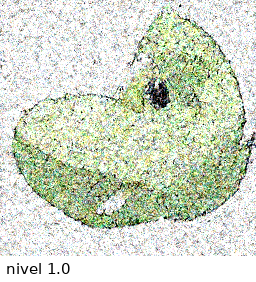

Guardado: /content/drive/MyDrive/Taller_MUTAR/sesion3/pokemon_disolver_s7_grandes.png


'/content/drive/MyDrive/Taller_MUTAR/sesion3/pokemon_disolver_s7_grandes.png'

In [13]:
#@title 5.1 Disolver una imagen
MODELO_DISOLVER = "pokemon" #@param ["bedroom", "pokemon", "church", "cityscapes", "art_painting", "landscape", "flowers", "clevr", "ffhq"]
SEMILLA_D = 7 #@param {type:"integer"}
CAPAS_D = "grandes (textura)" #@param ["todas", "chicas (estructura)", "grandes (textura)"]
NIVELES = "1" #@param {type:"string"}

Gd = cargar(MODELO_DISOLVER)
niveles = [float(n) for n in NIVELES.split(",") if n.strip()]
imgs = [generar([ruido(SEMILLA_D)], Gd, nivel=n, capas=CAPAS_D)[0] for n in niveles]
hoja = grilla(imgs, [f"nivel {n}" for n in niveles], columnas=min(len(imgs), 5))
print(f"{MODELO_DISOLVER} · semilla {SEMILLA_D} · capas: {CAPAS_D}")
display(hoja)
guardar(hoja, f"{MODELO_DISOLVER}_disolver_s{SEMILLA_D}_{limpio(CAPAS_D.split()[0])}.png")

### 5.2 Lienzo expandido

El generador siempre empieza desde una grillita de **4 × 4**, que viene de la semilla, y la va agrandando hasta 256 × 256. Pero todas sus capas son **convolucionales**: kernels que recorren la imagen, sin importarles qué tan grande es (Sesión 1).

Entonces podemos hacer trampa: generamos la grillita de **varias semillas**, las pegamos una al lado de la otra, y dejamos que el resto de la red pinte **todo junto**. El modelo nunca vio una imagen así de grande, y la resuelve como puede: las habitaciones se continúan unas en otras, una cama se vuelve pared, una ventana aparece donde no debería. Una arquitectura que no cierra.

* **COLUMNAS × FILAS:** cuántas semillas a lo ancho y a lo alto. Cada una suma 256 px. 3 × 2 da una imagen de 768 × 512.
* **SEMILLA_INICIAL:** la primera semilla. Las demás siguen en orden (5, 6, 7, 8…). Cambiarla cambia todo el lienzo.
* **NIVEL_L:** puedes combinarlo con disolver.

bedroom · semillas 234 a 237 · 512 x 512 px


/tmp/ipykernel_1203/2839151098.py:10: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(a, "RGB")


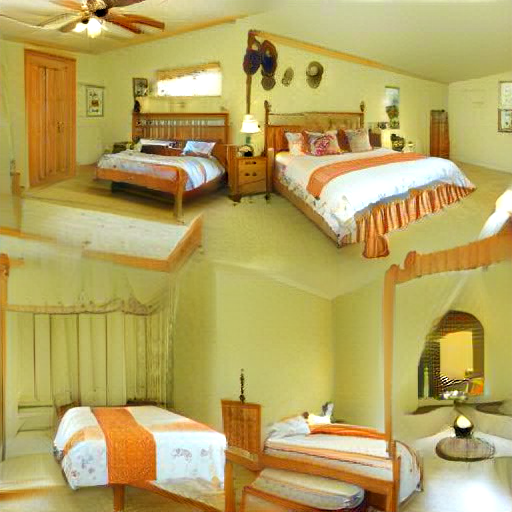

Guardado: /content/drive/MyDrive/Taller_MUTAR/sesion3/bedroom_lienzo_s234_2x2.png


'/content/drive/MyDrive/Taller_MUTAR/sesion3/bedroom_lienzo_s234_2x2.png'

In [33]:
#@title 5.2 Lienzo expandido
MODELO_LIENZO = "bedroom" #@param ["bedroom", "pokemon", "church", "cityscapes", "art_painting", "landscape", "flowers", "clevr", "ffhq"]
SEMILLA_INICIAL = 234 #@param {type:"integer"}
COLUMNAS = 2 #@param {type:"slider", min:1, max:6, step:1}
FILAS = 2 #@param {type:"slider", min:1, max:4, step:1}
NIVEL_L = 0 #@param {type:"slider", min:0, max:2, step:0.05}
CAPAS_L = "todas" #@param ["todas", "chicas (estructura)", "grandes (textura)"]

Gl = cargar(MODELO_LIENZO)
img = generar_lienzo(ruidos_lienzo(SEMILLA_INICIAL, COLUMNAS, FILAS), Gl, nivel=NIVEL_L, capas=CAPAS_L)
print(f"{MODELO_LIENZO} · semillas {SEMILLA_INICIAL} a {SEMILLA_INICIAL + COLUMNAS * FILAS - 1} · {img.width} x {img.height} px")
display(img)
guardar(img, f"{MODELO_LIENZO}_lienzo_s{SEMILLA_INICIAL}_{COLUMNAS}x{FILAS}" + (f"_n{NIVEL_L}" if NIVEL_L else "") + ".png")

## 6. Videos

Un video es una secuencia de imágenes. **Duración × FPS = cantidad de frames.** 10 segundos a 24 FPS son 240 imágenes.

FastGAN es muy rápida: con GPU genera cientos de imágenes por segundo. Un video de 1 minuto se hace en segundos. Por eso podemos hacer **videos largos**. (El lienzo expandido es más lento: cada frame es una imagen grande.)

**Para que el video sea más grande:** **AMPLIAR** (celda 6.0) agranda cada frame ×2 o ×4 para proyectar, pero no agrega detalle. Para más detalle, usa el lienzo (6.4).

Cada celda de video tiene su propio menú de modelo. Los frames se guardan como imágenes en una carpeta y sirven para la **Sesión 4 (FILM)**.

In [9]:
#@title 6.0 Formato del video (ejecutar antes de los videos)
FPS = 24 #@param [12, 24, 25, 30] {type:"raw"}
AMPLIAR = 2 #@param [1, 2, 4] {type:"raw"}
#@markdown CALIDAD: 18 = muy alta (archivo grande), 23 = buena, 28 = liviana (para WhatsApp)
CALIDAD = 18 #@param {type:"slider", min:14, max:30, step:1}

def ffmpeg():
    return shutil.which("ffmpeg") or __import__("imageio_ffmpeg").get_ffmpeg_exe()

def camino(claves, segundos_por_tramo, suave=True):
    # Lista de puntos intermedios entre cada clave y la siguiente.
    por_tramo = max(2, int(round(segundos_por_tramo * FPS)))
    puntos = []
    for a, b in zip(claves[:-1], claves[1:]):
        for k in range(por_tramo):
            t = suavizar(k / por_tramo) if suave else k / por_tramo
            puntos.append(slerp(a, b, t) if torch.is_tensor(a) else a + (b - a) * t)
    puntos.append(claves[-1])
    return puntos

def renderizar(nombre_video, puntos, dibujar, lote=None, ida_y_vuelta=False, gif=False):
    # dibujar: función que recibe una tanda de puntos y devuelve sus imágenes.
    carpeta = os.path.join(CARPETA, f"frames_{nombre_video}")
    shutil.rmtree(carpeta, ignore_errors=True)
    os.makedirs(carpeta)
    lote = lote or LOTE
    print(f"{len(puntos)} frames · {len(puntos) / FPS:.1f} s")
    n = 0
    for k in tqdm(range(0, len(puntos), lote), desc="Generando"):
        for im in dibujar(puntos[k:k + lote]):
            ampliar(im, AMPLIAR).save(os.path.join(carpeta, f"{n:06d}.jpg"), quality=95)
            n += 1
    print(f"Frames de {im.width * AMPLIAR} x {im.height * AMPLIAR} px")
    return montar_video(nombre_video, ida_y_vuelta=ida_y_vuelta, gif=gif)

def montar_video(nombre_video, fps=None, ida_y_vuelta=False, calidad=None, gif=False, mostrar=True):
    # Une los frames de la carpeta en un .mp4 (y opcionalmente un .gif liviano).
    fps, calidad = fps or FPS, calidad or CALIDAD
    frames = sorted(glob.glob(os.path.join(CARPETA, f"frames_{nombre_video}", "*.jpg")))
    if not frames:
        raise SystemExit(f"No hay frames para '{nombre_video}'.")
    if ida_y_vuelta:
        frames = frames + frames[-2:0:-1]
    tmp = "/content/_montaje"
    shutil.rmtree(tmp, ignore_errors=True); os.makedirs(tmp)
    for i, f in enumerate(frames):
        os.symlink(f, os.path.join(tmp, f"{i:06d}.jpg"))
    salida = os.path.join(CARPETA, f"{nombre_video}.mp4")
    subprocess.run([ffmpeg(), "-y", "-loglevel", "error", "-framerate", str(fps), "-i", f"{tmp}/%06d.jpg",
                    "-c:v", "libx264", "-preset", "medium", "-crf", str(calidad),
                    "-pix_fmt", "yuv420p", "-movflags", "+faststart", salida], check=True)
    mb = os.path.getsize(salida) / 1e6
    print(f"Video: {salida} · {len(frames)} frames · {len(frames) / fps:.1f} s · {mb:.1f} MB")
    if gif:
        salida_gif = os.path.join(CARPETA, f"{nombre_video}.gif")
        subprocess.run([ffmpeg(), "-y", "-loglevel", "error", "-i", salida, "-vf",
                        "fps=12,scale=384:-2:flags=lanczos,split[a][b];[a]palettegen[p];[b][p]paletteuse",
                        salida_gif], check=True)
        print(f"GIF: {salida_gif} · {os.path.getsize(salida_gif) / 1e6:.1f} MB")
    if mostrar and mb < 40:
        display(Video(salida, embed=True, width=512))
    elif mostrar:
        print("(El video es muy pesado para mostrarlo aquí: descárgalo en la sección 7 o búscalo en tu Drive.)")
    return salida

print(f"Formato listo: {FPS} FPS · ampliar x{AMPLIAR}")

Formato listo: 24 FPS · ampliar x2


### 6.1 De una semilla a otra

El video empieza en la **SEMILLA_A** y termina en la **SEMILLA_B**. En el camino, la imagen se transforma de a poco.

* **SUAVIZADO:** el viaje arranca y frena despacio, en vez de ir a velocidad constante.
* **IDA_Y_VUELTA:** vuelve de B a A. El video queda del doble de largo y se puede repetir en bucle.

In [41]:
#@title 6.1 Video entre dos semillas
MODELO_V1 = "bedroom" #@param ["bedroom", "pokemon", "church", "cityscapes", "art_painting", "landscape", "flowers", "clevr", "ffhq"]
NOMBRE_VIDEO = "habitación12_345" #@param {type:"string"}
SEMILLA_A = 12 #@param {type:"integer"}
SEMILLA_B = 345 #@param {type:"integer"}
DURACION_SEG = 8 #@param {type:"slider", min:2, max:60, step:1}
SUAVIZADO = True #@param {type:"boolean"}
IDA_Y_VUELTA = True #@param {type:"boolean"}
HACER_GIF = False #@param {type:"boolean"}

G1 = cargar(MODELO_V1)
print(f"{MODELO_V1}: semilla {SEMILLA_A} → semilla {SEMILLA_B}")
renderizar(limpio(NOMBRE_VIDEO), camino([ruido(SEMILLA_A), ruido(SEMILLA_B)], DURACION_SEG, SUAVIZADO),
           lambda zs: generar(zs, G1), ida_y_vuelta=IDA_Y_VUELTA, gif=HACER_GIF)

Output hidden; open in https://colab.research.google.com to view.

### 6.2 Viaje largo por varias semillas

Para videos largos: escribe un **recorrido** de semillas separadas por comas y el video pasa por todas, una tras otra. Con **VOLVER_AL_INICIO** la última vuelve a la primera y el video queda en bucle perfecto.

Si dejas el recorrido vacío, se eligen **CANTIDAD_AL_AZAR** semillas al azar.

* **SEGUNDOS_POR_TRAMO:** cuánto dura cada viaje entre dos semillas. 8 semillas × 5 segundos = 40 segundos.

In [ ]:
#@title 6.2 Viaje largo por varias semillas
MODELO_V2 = "bedroom" #@param ["bedroom", "pokemon", "church", "cityscapes", "art_painting", "landscape", "flowers", "clevr", "ffhq"]
NOMBRE_VIAJE = "viaje_habitaciones" #@param {type:"string"}
RECORRIDO = "0, 31, 7, 102, 55, 13" #@param {type:"string"}
CANTIDAD_AL_AZAR = 8 #@param {type:"slider", min:2, max:40, step:1}
SEGUNDOS_POR_TRAMO = 5 #@param {type:"slider", min:1, max:30, step:1}
VOLVER_AL_INICIO = True #@param {type:"boolean"}
HACER_GIF_VJ = False #@param {type:"boolean"}

G2 = cargar(MODELO_V2)
if RECORRIDO.strip():
    semillas = [int(s) for s in RECORRIDO.split(",") if s.strip()]
else:
    semillas = list(np.random.RandomState(int(time.time())).randint(0, 100000, CANTIDAD_AL_AZAR))
if len(semillas) < 2:
    raise SystemExit("Escribe al menos dos semillas separadas por comas.")
claves = [ruido(s) for s in semillas]
if VOLVER_AL_INICIO:
    claves.append(claves[0])
print(f"{MODELO_V2}: " + " → ".join(str(s) for s in semillas) + (f" → {semillas[0]}" if VOLVER_AL_INICIO else ""))
renderizar(limpio(NOMBRE_VIAJE), camino(claves, SEGUNDOS_POR_TRAMO), lambda zs: generar(zs, G2), gif=HACER_GIF_VJ)

### 6.3 Video: disolverse

La misma semilla, quieta, mientras el **nivel** de disolución sube de **NIVEL_DESDE** a **NIVEL_HASTA**. Con **IDA_Y_VUELTA** se disuelve y se vuelve a armar.

* **RUIDO_QUIETO** (marcado): el ruido que se agrega es siempre el mismo y solo cambia su intensidad. La imagen se deshace con suavidad.
* **RUIDO_QUIETO** (desmarcado): el ruido cambia en cada frame. La imagen *hierve*.

In [34]:
#@title 6.3 Video: disolverse
MODELO_V3 = "pokemon" #@param ["bedroom", "pokemon", "church", "cityscapes", "art_painting", "landscape", "flowers", "clevr", "ffhq"]
NOMBRE_DISOLVER = "criatura_disolviendose" #@param {type:"string"}
SEMILLA_V3 = 236 #@param {type:"integer"}
CAPAS_V3 = "todas" #@param ["todas", "chicas (estructura)", "grandes (textura)"]
NIVEL_DESDE = 0 #@param {type:"number"}
NIVEL_HASTA = 2 #@param {type:"number"}
DURACION_V3 = 6 #@param {type:"slider", min:2, max:60, step:1}
RUIDO_QUIETO = True #@param {type:"boolean"}
IDA_Y_VUELTA_V3 = True #@param {type:"boolean"}
HACER_GIF_V3 = False #@param {type:"boolean"}

G3 = cargar(MODELO_V3)
z = ruido(SEMILLA_V3)
niveles = camino([float(NIVEL_DESDE), float(NIVEL_HASTA)], DURACION_V3)
print(f"{MODELO_V3} · semilla {SEMILLA_V3} · nivel {NIVEL_DESDE} → {NIVEL_HASTA} · capas: {CAPAS_V3}")
renderizar(limpio(NOMBRE_DISOLVER), niveles,
           lambda ns: [generar([z], G3, nivel=n, capas=CAPAS_V3, ruido_quieto=RUIDO_QUIETO)[0] for n in ns],
           ida_y_vuelta=IDA_Y_VUELTA_V3, gif=HACER_GIF_V3)

Output hidden; open in https://colab.research.google.com to view.

### 6.4 Video: viajar por el lienzo expandido

Un lienzo expandido (sección 5.2) que se transforma en otro: cada casilla viaja de su semilla a una nueva. Es el video más lento, porque cada frame es una imagen grande. Empieza con pocos segundos y AMPLIAR en 1 (celda 6.0).

* **LIENZO_A** y **LIENZO_B:** las semillas iniciales de los dos lienzos (como SEMILLA_INICIAL en 5.2).

In [35]:
#@title 6.4 Video del lienzo expandido
MODELO_V4 = "bedroom" #@param ["bedroom", "pokemon", "church", "cityscapes", "art_painting", "landscape", "flowers", "clevr", "ffhq"]
NOMBRE_LIENZO = "habitaciones_infinitas" #@param {type:"string"}
LIENZO_A = 0 #@param {type:"integer"}
LIENZO_B = 100 #@param {type:"integer"}
COLUMNAS_V4 = 3 #@param {type:"slider", min:1, max:6, step:1}
FILAS_V4 = 2 #@param {type:"slider", min:1, max:4, step:1}
DURACION_V4 = 6 #@param {type:"slider", min:2, max:60, step:1}
IDA_Y_VUELTA_V4 = True #@param {type:"boolean"}
HACER_GIF_V4 = False #@param {type:"boolean"}

G4 = cargar(MODELO_V4)
puntos = camino([ruidos_lienzo(LIENZO_A, COLUMNAS_V4, FILAS_V4), ruidos_lienzo(LIENZO_B, COLUMNAS_V4, FILAS_V4)], DURACION_V4)
print(f"{MODELO_V4}: lienzo {LIENZO_A} → lienzo {LIENZO_B} · {COLUMNAS_V4} x {FILAS_V4} semillas")
renderizar(limpio(NOMBRE_LIENZO), puntos, lambda ps: [generar_lienzo(p, G4) for p in ps], lote=4,
           ida_y_vuelta=IDA_Y_VUELTA_V4, gif=HACER_GIF_V4)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
#@title 6.5 (Opcional) Volver a montar un video con otros ajustes
#@markdown Cambia FPS, calidad, ida y vuelta o GIF sin volver a generar los frames.
#@markdown Ejemplo: los mismos frames a 12 FPS dan un video del doble de largo y más lento.
NOMBRE = "habitacion_0_a_31" #@param {type:"string"}
FPS_MONTAJE = 24 #@param [8, 12, 15, 24, 25, 30] {type:"raw"}
IDA_Y_VUELTA_M = False #@param {type:"boolean"}
CALIDAD_M = 18 #@param {type:"slider", min:14, max:30, step:1}
HACER_GIF_M = True #@param {type:"boolean"}

montar_video(limpio(NOMBRE), fps=FPS_MONTAJE, ida_y_vuelta=IDA_Y_VUELTA_M, calidad=CALIDAD_M, gif=HACER_GIF_M)

## 7. Descargar tus resultados

Descarga un `.zip` con imágenes, videos y GIFs. Los frames sueltos no se incluyen por defecto porque pesan mucho; si los quieres para la Sesión 4, marca INCLUIR_FRAMES. Si conectaste Drive (celda 0.1), ya está todo guardado en `Taller_MUTAR/sesion3`.

In [ ]:
#@title 7. Descargar todo en un .zip
INCLUIR_FRAMES = False #@param {type:"boolean"}

tmp = "/content/_para_zip"  # copia temporal para armar el zip
shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(CARPETA, tmp, ignore=None if INCLUIR_FRAMES else shutil.ignore_patterns("frames_*"))
ruta_zip = shutil.make_archive("/content/sesion3_projectedgan", "zip", tmp)
print(f"{ruta_zip} ({os.path.getsize(ruta_zip) / 1e6:.1f} MB)")
if os.path.getsize(ruta_zip) > 500e6:
    print("Es muy pesado para descargar desde el navegador: conecta Drive en la celda 0.1, ahí ya queda todo guardado.")
files.download(ruta_zip)

---
## Glosario

* **Projected GAN:** una GAN cuyo discriminador mira las imágenes a través de una red ya entrenada (EfficientNet). Aprende mucho más rápido y con pocos datos.
* **EfficientNet:** una red convolucional de clasificación, como Inception, entrenada con ImageNet. Projected GAN usa sus capas intermedias, no su respuesta final.
* **FastGAN:** el generador liviano que usan estos modelos. Pensado para entrenar con pocas imágenes.
* **Semilla:** el número que fija los 256 números al azar del ruido. Misma semilla = misma imagen.
* **Espacio latente:** el espacio de todos los ruidos posibles. Aquí tiene 256 dimensiones. Puntos cercanos dan imágenes parecidas.
* **Vecindario:** las imágenes que están cerca de una semilla en el espacio latente.
* **Disolver:** agregar ruido dentro del generador, en capas chicas (estructura) o grandes (textura).
* **Lienzo expandido:** coser el comienzo de varias semillas para que el generador pinte una imagen más grande de lo que aprendió.
* **Interpolación:** viajar de un punto a otro en pasos pequeños. Cada paso es un frame del video.
* **Truncación:** estos modelos no la tienen, porque normalizan el ruido. Ver la sección "¿Qué es Projected GAN?".

---
### Para la Sesión 4

Guarda al menos:

1. Dos o tres imágenes que te gusten.
2. Un video.

Los vamos a usar en la Sesión 4 (FILM) para crear transiciones entre las imágenes de todo el taller.

### Para seguir explorando

* Artículo: Sauer, Chitta, Müller y Geiger, *Projected GANs Converge Faster* (NeurIPS 2021): https://arxiv.org/abs/2111.01007
* Repositorio oficial: https://github.com/autonomousvision/projected_gan
* FastGAN: Liu y equipo, *Towards Faster and Stabilized GAN Training for High-fidelity Few-shot Image Synthesis* (2021): https://arxiv.org/abs/2101.04775

*Taller Arqueología de la I.A. generativa · Máquinas de Estados Infinitos*